<a href="https://colab.research.google.com/github/nattaponm/Teach_Tdating_strom_tracks_HID_CloudProperties/blob/main/notebooks/02_track_footprints.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: Footprint ของเมฆตามเส้นทางพายุ
### Storm footprints (swept areas) at 15, 10 and 5 minutes — geometry, agreement between resolutions and damage reports

⏱️ เวลาเรียนโดยประมาณ **60 นาที** | ต้องผ่าน: Notebook 1

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **สร้าง footprint** ของแต่ละเส้นทาง จากพื้นที่ของเซลล์ทุกเวลา (union) และเทียบกับ convex hull
2. **ทำแผนที่ footprint** ของทั้งสามความละเอียด และแผนที่ซูมรายเวลาของพายุที่ก่อความเสียหาย
3. **วัดความสอดคล้องระหว่างความละเอียด** ด้วย IoU (Jaccard index)
4. **ประเมินว่า footprint ครอบคลุมจุดรายงานความเสียหาย** ได้ดีแค่ไหน
5. **ส่งออก footprint เป็น GeoPackage** เพื่อใช้ใน QGIS (ซ้อนกับตำบล พื้นที่เกษตร ประชากร)

## 📖 1. แนวคิดและสมการ

### 1.1 Footprint (swept area)
ถ้า $C_t$ คือชุด pixel ของเซลล์ในเส้นทางหนึ่ง ณ เวลา $t$
$$ F = \bigcup_{t} C_t,\qquad A_F = |F| \times 1\ \mathrm{km}^2 $$
- ที่ Δt = 15 นาที เซลล์ขนาด ~10 km ที่เคลื่อนที่ 10 km ต่อภาพ อาจ **ไม่ซ้อนกัน** → footprint เป็น "หย่อม ๆ" มีช่องว่าง
- ภาพที่ถี่ขึ้นเติมช่องว่างเหล่านี้ (แต่เป็นภาพสังเคราะห์!)

### 1.2 รูปทรงของ footprint
$$ \text{compactness} = \frac{A_F}{A_{hull}} \quad (0 < \cdot \le 1) $$
ค่าใกล้ 1 = footprint ทึบเป็นก้อน, ค่าต่ำ = เป็นแถบยาวโค้งหรือขาดเป็นช่วง ($A_{hull}$ = พื้นที่ convex hull)

### 1.3 ความสอดคล้องระหว่างความละเอียด (IoU / Jaccard)
$$ \mathrm{IoU}(F_a, F_b) = \frac{|F_a \cap F_b|}{|F_a \cup F_b|} $$
จับคู่เส้นทางที่ Δt = 15 นาทีกับเส้นทางที่ Δt = 5 นาทีที่มี IoU สูงสุด

### 1.4 การครอบคลุมจุดรายงาน (hit rate)
จุดรายงาน $i$ "ถูกครอบคลุม" ถ้าอยู่ห่างจาก footprint ไม่เกิน $d$ km (ตำแหน่งในข่าวเป็นระดับตำบล จึงเผื่อ $d$ = 5 km)
$$ \mathrm{HR} = \frac{1}{N}\sum_i \mathbb{1}\big[\mathrm{dist}(p_i, F) \le d\big] $$

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–4 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Tdating_strom_tracks_HID_CloudProperties"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio scikit-image
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "track_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
DER = os.path.join(DATA, "derived")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import track_tools as tt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Tdating_strom_tracks_HID_CloudProperties/data


In [2]:
terr = tt.load_terrain(os.path.join(DER, "KKN_20240503_terrain_1km.nc"))
SETS = {}
for dt in (15, 10, 5):
    S = tt.load_set(DER, tt.MAIN[dt])
    C = tt.add_motion(tt.cell_table(S["labels"], S["Z"], S["times"], S["meta"], terrain=terr), terr, S["meta"])
    T = tt.track_table(C)
    keep = T.index[T.lifetime_min >= 30]                                   # เกณฑ์อายุจริงจาก NB1
    SETS[dt] = {**S, "C": C[C.track_id.isin(keep)], "T": T.loc[keep]}
meta = SETS[15]["meta"]
reports = kt.load_reports(DATA, meta)
shape = SETS[15]["Z"].shape[1:]
date0 = SETS[15]["times"][0].normalize()
print({dt: f"{len(S['T'])} เส้นทาง (อายุ ≥ 30 นาที)" for dt, S in SETS.items()})

{15: '59 เส้นทาง (อายุ ≥ 30 นาที)', 10: '62 เส้นทาง (อายุ ≥ 30 นาที)', 5: '68 เส้นทาง (อายุ ≥ 30 นาที)'}


## 🧩 3. สร้าง footprint ของทุกเส้นทาง

In [3]:
FP, GDF = {}, {}
for dt, S in SETS.items():
    FP[dt] = tt.footprint_masks(S["labels"], track_ids=set(S["T"].index))
    GDF[dt] = tt.footprint_polygons(FP[dt], meta, shape, extra=S["T"][["lifetime_min", "path_km", "Zmax_obs", "start"]])
    GDF[dt]["dt_min"] = dt
summary = pd.DataFrame({dt: {"tracks": len(g), "median area (km²)": g.area_km2.median(), "total area (km²)": g.area_km2.sum(),
                             "median compactness": g.compactness.median(),
                             "parts per footprint": g.geometry.apply(lambda x: len(getattr(x, "geoms", [x]))).mean()}
                        for dt, g in GDF.items()}).T.round(2)
summary

,tracks,median area (km²),total area (km²),median compactness,parts per footprint
15,59.0,251.0,16853.0,0.64,1.37
10,62.0,220.5,21791.0,0.74,1.08
5,68.0,283.5,28062.0,0.79,1.00


- ที่ Δt = 15 นาที footprint ของเส้นทางเดียว **แตกเป็นหลายชิ้น** (parts > 1) เพราะเซลล์ไม่ซ้อนกันระหว่างภาพ
- ที่ Δt = 5 นาที ชิ้นส่วนเชื่อมกันเป็นแถบต่อเนื่อง พื้นที่รวมจึงมากขึ้น — **พื้นที่ที่เพิ่มขึ้นมาจากภาพสังเคราะห์ทั้งหมด**

## 🗺️ 4. แผนที่ footprint ทั้งสามความละเอียด

บันทึกรูปแล้ว: figures/nb2_footprints_three_resolutions.png, figures/nb2_footprints_three_resolutions.pdf


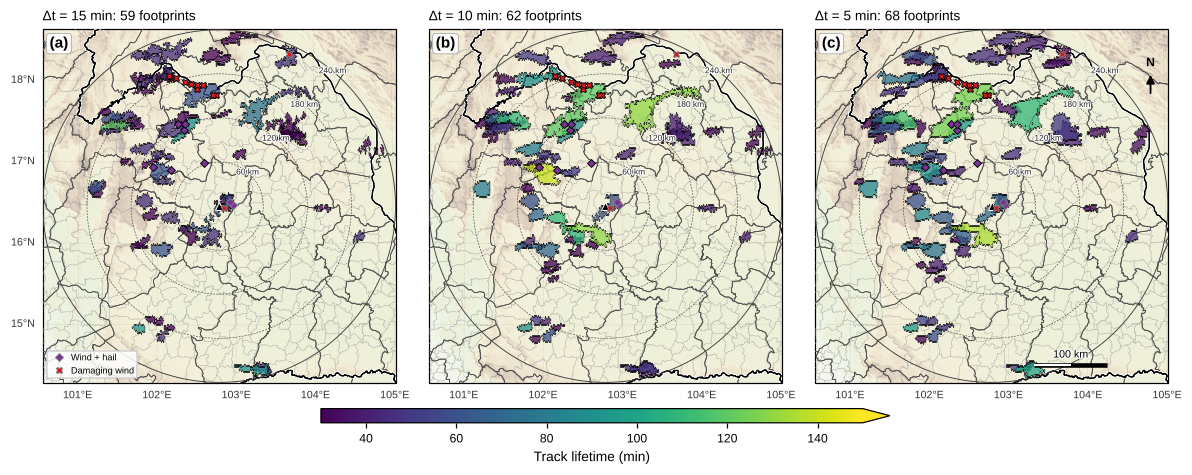

In [4]:
fig, axs = mp.map_panels(1, 3, meta, panel_width=3.6)
for k, (ax, dt) in enumerate(zip(axs, (15, 10, 5))):
    ax.set_extent(mp.extent_of(meta), crs=mp.get_crs(meta))
    mp.add_terrain(ax, meta, alpha=0.6)
    mp.add_basemap(ax, meta, labels=("left", "bottom") if k == 0 else ("bottom",))
    sm = tt.plot_footprints(ax, GDF[dt], meta, column="lifetime_min", cmap="viridis", vmin=30, vmax=150)
    mp.add_reports(ax, reports, legend=(k == 0), ms=4)
    ax.set_title(f"Δt = {dt} min: {len(GDF[dt])} footprints", loc="left", fontsize=9)
    if k == 2:
        mp.add_scalebar(ax); mp.add_north_arrow(ax)
mp.panel_labels(axs)
cb = fig.colorbar(sm, ax=list(axs), orientation="horizontal", shrink=0.5, pad=0.02, aspect=40, extend="max")
cb.set_label("Track lifetime (min)")
mp.save_figure(fig, "nb2_footprints_three_resolutions")
plt.show()

## 🔎 5. ซูมพายุนากลาง: เซลล์รายเวลา + footprint

บันทึกรูปแล้ว: figures/nb2_naklang_footprint_zoom.png, figures/nb2_naklang_footprint_zoom.pdf


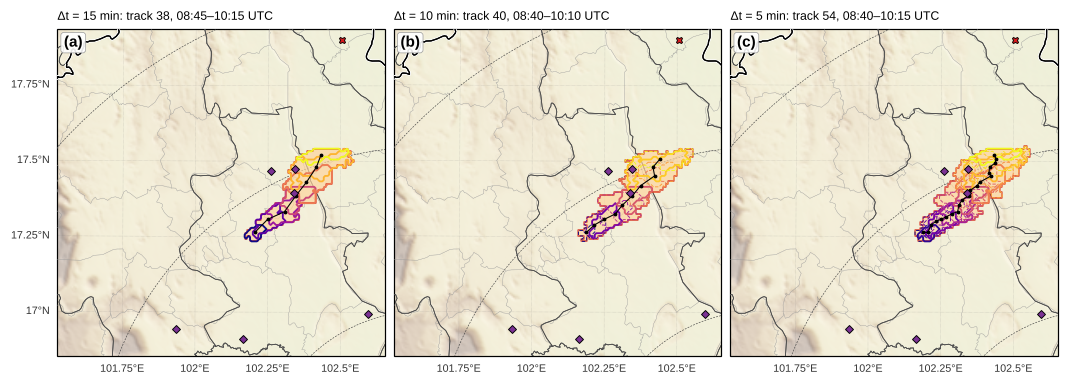

In [5]:
s_nk = kt.site(reports, "Na Klang")
t_rep = kt.report_time_utc(s_nk, date0)
ZB = kt.box_around(meta, s_nk["lon"] - 0.25, s_nk["lat"], 60)
fig, axs = mp.map_panels(1, 3, meta, panel_width=3.2, zoom=ZB)
crs = mp.get_crs(meta)
import matplotlib as mpl
for k, (ax, dt) in enumerate(zip(axs, (15, 10, 5))):
    S = SETS[dt]
    near = tt.tracks_near(S["T"], S["C"], s_nk["lon"], s_nk["lat"], t_ref=t_rep, radius_km=15, window_min=45, meta=meta)
    ax.set_extent(ZB, crs=crs); mp.add_terrain(ax, meta, alpha=0.6); mp.add_basemap(ax, meta, labels=("left", "bottom") if k == 0 else ("bottom",))
    if not near.empty:
        tid = int(near.index[0])
        g = GDF[dt].set_index("track_id").loc[[tid]]
        ax.add_geometries(g.geometry, crs=crs, facecolor="#fdd49e", edgecolor="#d7301f", linewidth=1.0, alpha=0.7, zorder=5)
        ti = list(S["times"])
        sel = [i for i, t in enumerate(ti) if (S["labels"][i] == tid + 1).any()]
        cm = mpl.colormaps["plasma"]
        for n_, i in enumerate(sel):
            m = (S["labels"][i] == tid + 1).astype(float)
            ax.contour(meta["x"], meta["y"], m, levels=[0.5], colors=[cm(n_ / max(len(sel) - 1, 1))],
                       linewidths=1.2 if S["observed"][i] else 0.6, linestyles="-" if S["observed"][i] else "--",
                       transform=crs, zorder=6)
        g_c = S["C"].query("track_id == @tid")
        ax.plot(g_c.cx, g_c.cy, "k.-", ms=3, lw=0.7, transform=crs, zorder=7)
        ax.set_title(f"Δt = {dt} min: track {tid}, {g_c.time.iloc[0]:%H:%M}–{g_c.time.iloc[-1]:%H:%M} UTC", loc="left", fontsize=8)
    mp.add_reports(ax, reports, legend=False, ms=4)
mp.panel_labels(axs)
mp.save_figure(fig, "nb2_naklang_footprint_zoom")
plt.show()

**อ่านภาพ:** พื้นส้ม = footprint, เส้นทึบ = ขอบเซลล์ในภาพจริง, เส้นประ = ขอบเซลล์ในภาพสังเคราะห์ (สีจากม่วง → เหลือง ตามเวลา)
เห็นได้ชัดว่าเส้นประ "เติม" ช่องว่างระหว่างเส้นทึบ — footprint ที่ 5 นาทีจึงต่อเนื่องกว่า

## 🔗 6. ความสอดคล้องระหว่างความละเอียด (IoU)

บันทึกรูปแล้ว: figures/nb2_iou_hist.png, figures/nb2_iou_hist.pdf


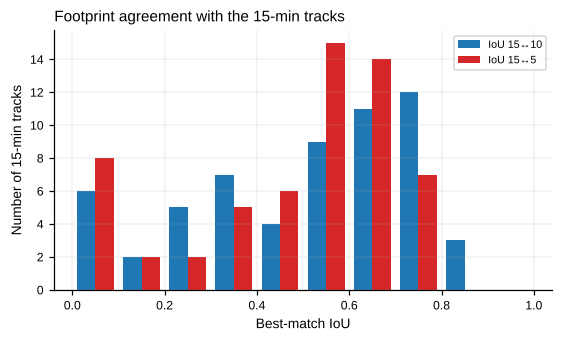

,IoU 15↔10,IoU 15↔5
count,59.00,59.00
mean,0.50,0.48
std,0.24,0.22
min,0.00,0.00
25%,0.32,0.38
50%,0.57,0.54
75%,0.70,0.64
max,0.81,0.78


In [6]:
m15_5 = tt.match_tracks(FP[15], FP[5], min_iou=0.05)
m15_10 = tt.match_tracks(FP[15], FP[10], min_iou=0.05)
iou = pd.DataFrame({"IoU 15↔10": m15_10["iou"], "IoU 15↔5": m15_5["iou"]})
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
ax.hist([iou["IoU 15↔10"], iou["IoU 15↔5"]], bins=np.linspace(0, 1, 11), label=list(iou.columns), color=["tab:blue", "tab:red"])
ax.set_xlabel("Best-match IoU"); ax.set_ylabel("Number of 15-min tracks"); ax.legend(fontsize=7); ax.grid(lw=0.3, alpha=0.5)
ax.set_title("Footprint agreement with the 15-min tracks", loc="left")
mp.save_figure(fig, "nb2_iou_hist")
plt.show()
iou.describe().round(2)

- IoU มัธยฐานบอกว่า footprint ของเส้นทางเดียวกัน "ซ้อนกัน" แค่ไหนเมื่อเปลี่ยนความละเอียด
- IoU ต่ำมักเกิดเมื่อ (1) เส้นทาง 5 นาทีเชื่อมสองเส้นทางของ 15 นาทีเข้าด้วยกัน หรือ (2) T-DaTing แยกเซลล์ต่างกันหลัง split/merge

## 🎯 7. Footprint ครอบคลุมจุดรายงานกี่จุด?

In [7]:
import geopandas as gpd
pts = gpd.GeoDataFrame(reports, geometry=gpd.points_from_xy(reports["x"], reports["y"]), crs=meta["projection"])
hit = {}
for dt, g in GDF.items():
    U = g.geometry.union_all() if hasattr(g.geometry, "union_all") else g.geometry.unary_union
    d = pts.geometry.distance(U) / 1000
    hit[f"dist_{dt}min_km"] = d.round(1)
cov = pd.concat([reports[["id", "district", "hazard", "time_LT", "range_km"]].round(0), pd.DataFrame(hit)], axis=1)
hr = {dt: float((cov[f"dist_{dt}min_km"] <= 5).mean()) for dt in (15, 10, 5)}
print("hit rate (ระยะ ≤ 5 km):", {k: f"{v:.0%}" for k, v in hr.items()})
cov

hit rate (ระยะ ≤ 5 km): {15: '84%', 10: '79%', 5: '84%'}


,id,district,hazard,time_LT,range_km,dist_15min_km,dist_10min_km,dist_5min_km
0,1,Phu Kradueng,ลมกระโชกแรง;ลูกเห็บ,14:00,105.0,0.2,0.0,0.0
1,2,Non Sang,ลมกระโชกแรง;ลูกเห็บ,16:30,62.0,38.7,16.2,16.2
2,3,Si Bun Rueang,ลมกระโชกแรง;ลูกเห็บ,16:30,83.0,0.2,0.1,0.0
3,4,Na Klang,ลมกระโชกแรง;ลูกเห็บ,16:30,114.0,0.0,0.0,0.0
4,5,Suwannakhuha,ลมกระโชกแรง;ลูกเห็บ,16:30,125.0,0.1,0.0,0.0
5,6,Suwannakhuha,ลมกระโชกแรง;ลูกเห็บ,16:30,121.0,0.0,0.0,0.0
6,7,Si Chiang Mai,ลมแรง,17:00,162.0,0.0,0.0,0.0
7,8,Si Chiang Mai,ลมแรง,17:00,166.0,2.2,2.0,2.0
8,9,Si Chiang Mai,ลมแรง,17:00,168.0,3.6,3.6,3.6
9,10,Si Chiang Mai,ลมแรง,17:00,171.0,6.7,6.7,6.7


## 💾 8. ส่งออกเป็น GeoPackage

In [8]:
os.makedirs("output", exist_ok=True)
allg = pd.concat([g.assign(start=g["start"].astype(str)) for g in GDF.values()], ignore_index=True)
allg = gpd.GeoDataFrame(allg, geometry="geometry", crs=meta["projection"]).to_crs("EPSG:4326")
out = "output/KKN_20240503_track_footprints.gpkg"
for dt in (15, 10, 5):
    allg[allg.dt_min == dt].to_file(out, layer=f"footprints_{dt:02d}min", driver="GPKG")
print("บันทึก:", out, "| layers:", [f"footprints_{dt:02d}min" for dt in (15, 10, 5)])

บันทึก: output/KKN_20240503_track_footprints.gpkg | layers: ['footprints_15min', 'footprints_10min', 'footprints_05min']


---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 2.1: footprint ยาวขึ้น หรือ "ทึบ" ขึ้น?
สำหรับเส้นทางที่จับคู่ได้ระหว่าง 15 และ 5 นาที (IoU ≥ 0.2) เปรียบเทียบ (1) พื้นที่ footprint (2) compactness (3) จำนวนชิ้นส่วน
ด้วย boxplot และหาอัตราส่วนพื้นที่ $A_{5}/A_{15}$

**คำถาม:** พื้นที่ที่เพิ่มขึ้นมาจากการ "เติมช่องว่าง" หรือจาก "เส้นทางยาวขึ้น"? ดูจากตัวชี้วัดใด

<details>
<summary><b>💡 คำใบ้</b></summary>

- `pairs = m15_5[m15_5.iou >= 0.2]` แล้วใช้ `GDF[15].set_index("track_id").loc[pairs.index]` กับ `GDF[5].set_index("track_id").loc[pairs.match]`
- จำนวนชิ้นส่วน: `len(getattr(geom, "geoms", [geom]))`

</details>

In [9]:
# ✍️ แบบฝึกหัด 2.1 — เขียนโค้ดของคุณที่นี่

จับคู่ได้ 49 เส้นทาง
area_ratio    1.65
path_ratio    1.64
compact_15    0.70
compact_5     0.76
parts_15      1.00
parts_5       1.00
dtype: float64


บันทึกรูปแล้ว: figures/nb2_ex21_footprint_change.png, figures/nb2_ex21_footprint_change.pdf


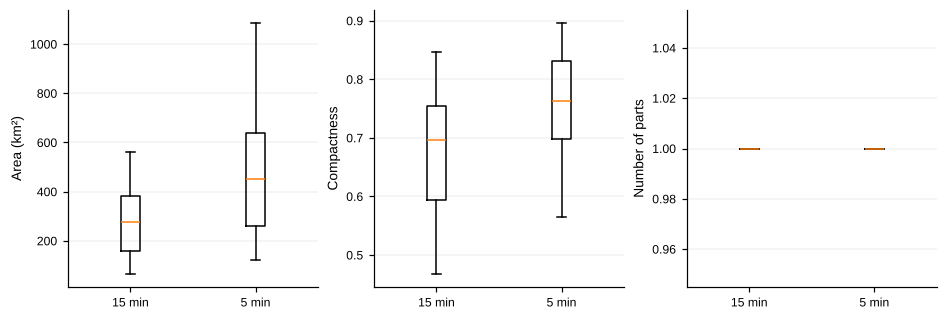

→ พื้นที่เพิ่ม ×1.65 ขณะที่ความยาวเส้นทางเพิ่ม ×1.64
  พื้นที่ที่เพิ่มขึ้นส่วนใหญ่มาจาก 'เส้นทางยาวขึ้น' (เริ่มเร็วขึ้น/จบช้าลง หรือเชื่อมกับเซลล์ข้างเคียง) มากกว่าการเติมช่องว่าง
  → ระวังการเชื่อมสองพายุเข้าด้วยกัน ตรวจด้วยแผนที่รายเวลาเหมือน section 5


In [10]:
#@title ✅ เฉลยแบบฝึกหัด 2.1
pairs = m15_5[m15_5.iou >= 0.2].dropna()
g15 = GDF[15].set_index("track_id").loc[pairs.index]
g05 = GDF[5].set_index("track_id").loc[pairs["match"].astype(int)]
cmp = pd.DataFrame({"area_15": g15.area_km2.values, "area_5": g05.area_km2.values,
                    "compact_15": g15.compactness.values, "compact_5": g05.compactness.values,
                    "parts_15": g15.geometry.apply(lambda x: len(getattr(x, "geoms", [x]))).values,
                    "parts_5": g05.geometry.apply(lambda x: len(getattr(x, "geoms", [x]))).values,
                    "path_15": g15.path_km.values, "path_5": g05.path_km.values})
cmp["area_ratio"] = cmp.area_5 / cmp.area_15
cmp["path_ratio"] = cmp.path_5 / cmp.path_15
print(f"จับคู่ได้ {len(cmp)} เส้นทาง")
print(cmp[["area_ratio", "path_ratio", "compact_15", "compact_5", "parts_15", "parts_5"]].median().round(2))
fig, axs = plt.subplots(1, 3, figsize=(8.5, 2.8), layout="constrained")
for ax, (a, b, lab) in zip(axs, (("area_15", "area_5", "Area (km²)"), ("compact_15", "compact_5", "Compactness"),
                                 ("parts_15", "parts_5", "Number of parts"))):
    ax.boxplot([cmp[a], cmp[b]], showfliers=False); ax.set_xticks([1, 2], ["15 min", "5 min"])
    ax.set_ylabel(lab); ax.grid(axis="y", lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb2_ex21_footprint_change")
plt.show()
ar, pr_ = cmp.area_ratio.median(), cmp.path_ratio.median()
print(f"→ พื้นที่เพิ่ม ×{ar:.2f} ขณะที่ความยาวเส้นทางเพิ่ม ×{pr_:.2f}")
if pr_ >= 0.8 * ar:
    print("  พื้นที่ที่เพิ่มขึ้นส่วนใหญ่มาจาก 'เส้นทางยาวขึ้น' (เริ่มเร็วขึ้น/จบช้าลง หรือเชื่อมกับเซลล์ข้างเคียง) มากกว่าการเติมช่องว่าง"
          "\n  → ระวังการเชื่อมสองพายุเข้าด้วยกัน ตรวจด้วยแผนที่รายเวลาเหมือน section 5")
else:
    print("  พื้นที่เพิ่มเร็วกว่าความยาว → ส่วนใหญ่มาจากการ 'เติมช่องว่าง' ระหว่างเซลล์ในภาพจริง")

### 🧪 แบบฝึกหัด 2.2: footprint ใดเป็นตัวแทนพื้นที่เสี่ยงได้ดีกว่า?
คำนวณ hit rate ที่ระยะ $d$ = 0, 2, 5, 10 km สำหรับทั้งสามความละเอียด และ **สัดส่วนพื้นที่เรดาร์ที่ footprint ครอบคลุม**
(พื้นที่ใหญ่ขึ้นย่อมครอบคลุมจุดได้มากขึ้น — ต้องชั่งกับ "การเตือนเกิน")

**คำถาม:** ความละเอียดใดให้สมดุลดีที่สุดระหว่าง hit rate กับพื้นที่ที่ต้องเตือน?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ระยะจาก `cov[f"dist_{dt}min_km"]`
- พื้นที่เรดาร์: `meta["coverage"].sum()` (km²) ; พื้นที่ footprint รวม: `U.area / 1e6`

</details>

In [11]:
# ✍️ แบบฝึกหัด 2.2 — เขียนโค้ดของคุณที่นี่

In [12]:
#@title ✅ เฉลยแบบฝึกหัด 2.2
A_cov = meta["coverage"].sum()
rows = []
for dt, g in GDF.items():
    U = g.geometry.union_all() if hasattr(g.geometry, "union_all") else g.geometry.unary_union
    r = {"dt_min": dt, "area_frac_%": 100 * U.area / 1e6 / A_cov}
    for d in (0, 2, 5, 10):
        r[f"HR_{d}km"] = float((cov[f"dist_{dt}min_km"] <= d).mean())
    rows.append(r)
hr_tab = pd.DataFrame(rows).set_index("dt_min").round(3)
print(hr_tab)
print(f"\n→ จุดรายงานที่อยู่ 'ใน' footprint (0 km): {hr_tab.loc[15, 'HR_0km']:.0%} (15 นาที) → {hr_tab.loc[5, 'HR_0km']:.0%} (5 นาที)"
      f" แต่ที่ระยะเผื่อ 5 km ใกล้กัน ({hr_tab.loc[15, 'HR_5km']:.0%} vs {hr_tab.loc[5, 'HR_5km']:.0%})"
      f"\n  ขณะที่พื้นที่ footprint เพิ่มจาก {hr_tab.loc[15, 'area_frac_%']:.1f}% เป็น {hr_tab.loc[5, 'area_frac_%']:.1f}% ของพื้นที่เรดาร์ → ได้ hit เพิ่มแลกกับพื้นที่เตือนที่มากขึ้น"
      "\n  จุดรายงานลมแรงที่หนองคายอยู่ไกล (~160 km) และเป็นตำแหน่งระดับตำบล → hit rate ไม่ได้วัดคุณภาพของเรดาร์อย่างเดียว")

        area_frac_%  HR_0km  HR_2km  HR_5km  HR_10km
dt_min                                              
15            8.369   0.474   0.737   0.842    0.895
10           10.584   0.526   0.684   0.789    0.895
5            13.178   0.737   0.789   0.842    0.895

→ จุดรายงานที่อยู่ 'ใน' footprint (0 km): 47% (15 นาที) → 74% (5 นาที) แต่ที่ระยะเผื่อ 5 km ใกล้กัน (84% vs 84%)
  ขณะที่พื้นที่ footprint เพิ่มจาก 8.4% เป็น 13.2% ของพื้นที่เรดาร์ → ได้ hit เพิ่มแลกกับพื้นที่เตือนที่มากขึ้น
  จุดรายงานลมแรงที่หนองคายอยู่ไกล (~160 km) และเป็นตำแหน่งระดับตำบล → hit rate ไม่ได้วัดคุณภาพของเรดาร์อย่างเดียว


### 🧪 แบบฝึกหัด 2.3: footprint บอกอะไรเกี่ยวกับรูปทรงของพายุ?
ใช้ GDF ที่ Δt = 15 นาที หาความสัมพันธ์ (Spearman) ระหว่าง compactness กับ (1) อายุ (2) ความยาวเส้นทาง (3) Zmax_obs
แล้วพลอต scatter ระบายสีตามอายุ

**คำถาม:** footprint ที่ "ยาวและแคบ" (compactness ต่ำ) เป็นพายุแบบไหน? เชื่อมกับความเร็วการเคลื่อนที่อย่างไร

<details>
<summary><b>💡 คำใบ้</b></summary>

- `from scipy.stats import spearmanr`
- ความเร็วอยู่ใน `SETS[15]["T"]["speed_kmh"]` (index = track_id)

</details>

In [13]:
# ✍️ แบบฝึกหัด 2.3 — เขียนโค้ดของคุณที่นี่

Spearman ρ กับ compactness: {'lifetime_min': np.float64(0.22), 'path_km': np.float64(-0.49), 'Zmax_obs': np.float64(0.28), 'speed_kmh': np.float64(-0.67)}


บันทึกรูปแล้ว: figures/nb2_ex23_compactness.png, figures/nb2_ex23_compactness.pdf


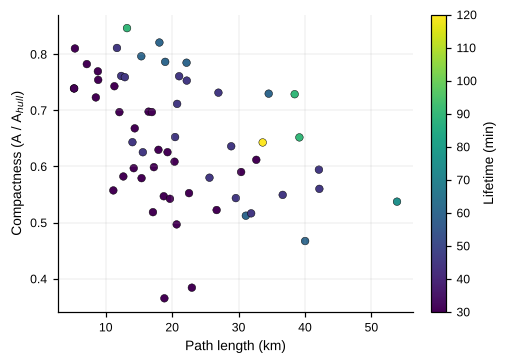

→ เส้นทางยาว/เคลื่อนเร็ว → footprint เป็นแถบแคบ compactness ต่ำ ; พายุเกือบอยู่กับที่ → footprint เป็นก้อน
  พายุที่อยู่กับที่นานก่อฝนสะสมสูงในจุดเดียว (เสี่ยงน้ำท่วมฉับพลัน) ขณะที่พายุเคลื่อนเร็วกระจายความเสียหายจากลมเป็นแนวยาว


In [14]:
#@title ✅ เฉลยแบบฝึกหัด 2.3
from scipy.stats import spearmanr
g = GDF[15].set_index("track_id").join(SETS[15]["T"][["speed_kmh"]])
res = {c: spearmanr(g["compactness"], g[c], nan_policy="omit")[0] for c in ("lifetime_min", "path_km", "Zmax_obs", "speed_kmh")}
print("Spearman ρ กับ compactness:", {k: round(v, 2) for k, v in res.items()})
fig, ax = plt.subplots(figsize=(4.5, 3.2), layout="constrained")
sc = ax.scatter(g["path_km"], g["compactness"], c=g["lifetime_min"], cmap="viridis", s=25, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=ax, label="Lifetime (min)")
ax.set_xlabel("Path length (km)"); ax.set_ylabel("Compactness (A / A$_{hull}$)"); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb2_ex23_compactness")
plt.show()
print("→ เส้นทางยาว/เคลื่อนเร็ว → footprint เป็นแถบแคบ compactness ต่ำ ; พายุเกือบอยู่กับที่ → footprint เป็นก้อน"
      "\n  พายุที่อยู่กับที่นานก่อฝนสะสมสูงในจุดเดียว (เสี่ยงน้ำท่วมฉับพลัน) ขณะที่พายุเคลื่อนเร็วกระจายความเสียหายจากลมเป็นแนวยาว")

---
## 📝 สรุป
- footprint = union ของเซลล์ทุกเวลา — ที่ 15 นาทีมักแตกเป็นหลายชิ้น ที่ 5 นาทีต่อเนื่องเป็นแถบ (เพราะภาพสังเคราะห์เติมช่องว่าง)
- IoU ใช้วัดว่าเส้นทางเดียวกันในความละเอียดต่างกัน "ซ้อนกัน" แค่ไหน และช่วยจับคู่เส้นทางข้ามความละเอียด
- hit rate ต่อจุดรายงานต้องอ่านคู่กับพื้นที่ที่ครอบคลุม และความไม่แน่นอนของตำแหน่งในข่าว
- footprint ส่งออกเป็น GeoPackage ใช้ต่อใน GIS ได้ทันที

### ❓ คำถามชวนคิด
1. ถ้าจะใช้ footprint เป็น "แผนที่พื้นที่เสี่ยงลูกเห็บ" สำหรับประกันภัยพืชผล ควรใช้ footprint ของเซลล์ ≥ 33 dBZ หรือเฉพาะแกน ≥ 45 dBZ? เพราะอะไร
2. footprint ที่ 5 นาทีเป็นผลจากการ "สมมติ" ว่าพายุเคลื่อนที่แบบ advection ระหว่างภาพ — กรณีใดที่สมมติฐานนี้ผิด (คำใบ้: พายุเกิดใหม่ข้างหน้า, การแพร่กระจายแบบ propagation)
3. ทำไมพายุบางเส้นทางจึงมี footprint ทับพื้นที่เดิมหลายครั้ง (training) และอันตรายอย่างไร

**🚀 ต่อยอด (ป.โท):** ซ้อน footprint กับขอบเขตตำบล (GADM/กรมการปกครอง) และข้อมูลความเสียหายของ ปภ. เพื่อสร้าง **ตาราง confusion ระดับตำบล** (ตำบลที่พายุผ่าน vs ตำบลที่มีรายงาน) และคำนวณ POD/FAR

### 📚 เอกสารอ้างอิง
- Lakshmanan, V., & Smith, T. (2010). An objective method of evaluating and devising storm-tracking algorithms. *Wea. Forecasting*, 25, 701–709.
- Cintineo, J. L., Smith, T. M., Lakshmanan, V., Brooks, H. E., & Ortega, K. L. (2012). An objective high-resolution hail climatology of the contiguous United States. *Wea. Forecasting*, 27, 1235–1248.
- Jaccard, P. (1912). The distribution of the flora in the alpine zone. *New Phytologist*, 11, 37–50.
- Pulkkinen, S., et al. (2019). Pysteps v1.0. *Geosci. Model Dev.*, 12, 4185–4219.